# Target grade distributions

Inspect each transformation on its own scale without running any model experiments. The same analysis students are used in every plot: duplicate rows and rows with missing values are removed, matching the experiment notebooks.

Each plot shows a density histogram and KDE. Axis scales and density units differ across modes, so curve heights should not be compared directly. KDE can distort density near the boundaries; use the histogram and summary alongside it. A more symmetric target distribution does not by itself establish better regression performance.


In [1]:
%matplotlib inline
import numpy as np
import pandas as pd
from IPython.display import display
from target_distributions import TARGET_MODES, plot_target_distributions

raw = pd.read_csv('student_grade_ses_dataset.csv')
analysis = raw.drop_duplicates().set_index('student_id').dropna()
grades = analysis['final_grade_pct']
print(f'Raw students: {len(raw):,}; analysis students: {len(analysis):,}')
print(f'Exactly 0: {grades.eq(0).sum()}; exactly 100: {grades.eq(100).sum()}')
display(analysis['grade_class'].value_counts().reindex(['A','B','C','D','F'], fill_value=0).rename('students').to_frame())
print(f"Low grades are underrepresented: {analysis['grade_class'].eq('F').mean():.1%} of analysis students are in F. This describes observed counts, not proof of sampling bias.")


Raw students: 12,025; analysis students: 8,785
Exactly 0: 0; exactly 100: 19


,students
grade_class,
A,157
B,1930
C,4532
D,2006
F,160


Low grades are underrepresented: 1.8% of analysis students are in F. This describes observed counts, not proof of sampling bias.


## Choose or add modes

Edit `modes` below to add, remove, or reorder transformations. Each callable receives the original grades. Supply `transform` and `xlabel`; `support` is optional and specifies the horizontal plotting range. The shared defaults are in `target_distributions.py`.

Logit uses the same endpoint adjustment as the logit experiment; square root matches the square-root experiment. Log1p is an additional visual exploration, not a fitted model experiment.


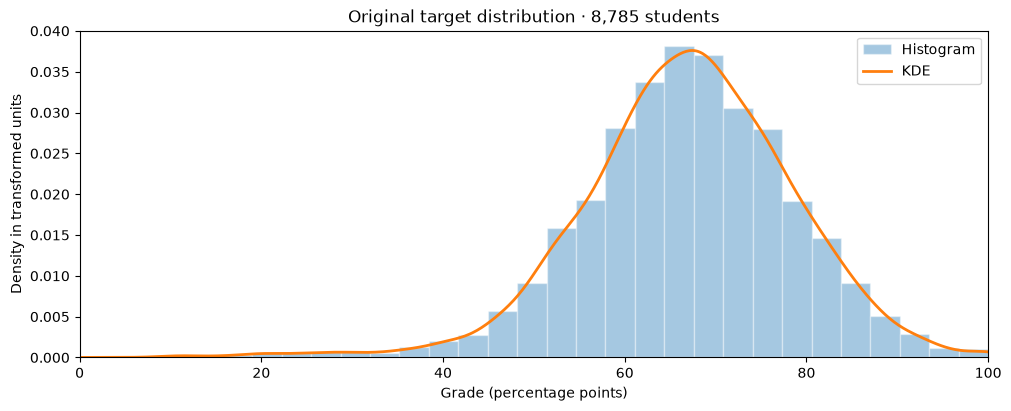

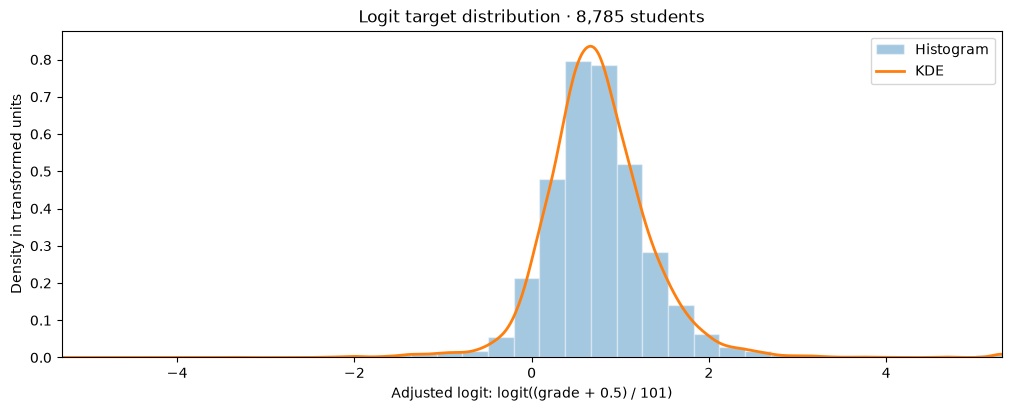

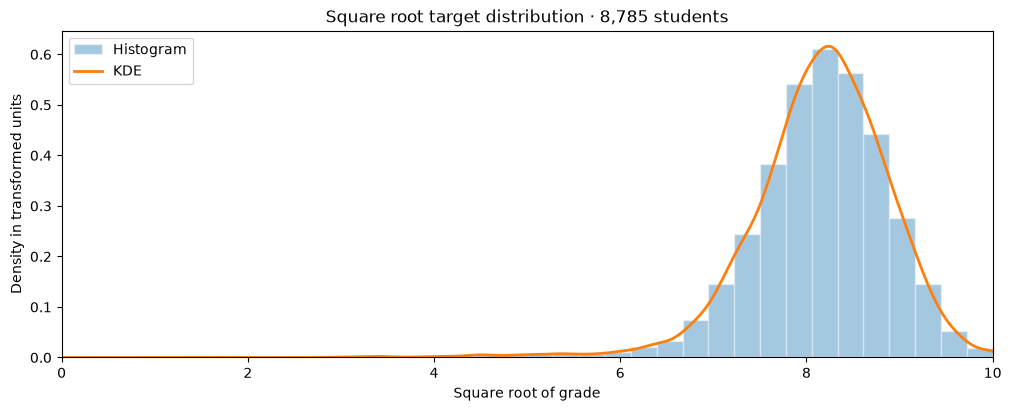

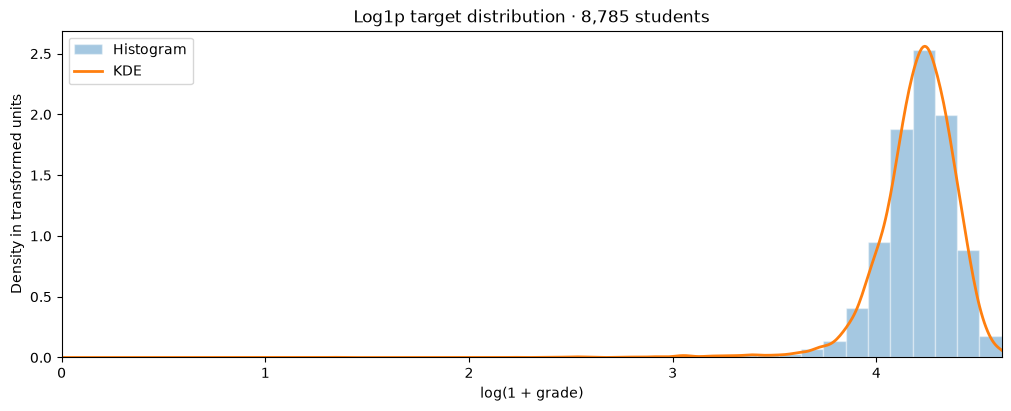

,students,minimum,median,maximum,mean,SD,skewness
mode,,,,,,,
Original,8785,2.800,67.300,100.000,66.874,11.659,-0.522
Logit,8785,-3.388,0.714,5.303,0.751,0.613,1.080
Square root,8785,1.673,8.204,10.000,8.143,0.754,-1.217
Log1p,8785,1.335,4.224,4.615,4.200,0.200,-2.453


In [2]:
modes = TARGET_MODES.copy()
# Example: uncomment to add cube root without modifying the plotting function.
# modes['Cube root'] = dict(transform=np.cbrt, xlabel='Cube root of grade', support=(0, np.cbrt(100)))
summary = plot_target_distributions(grades, modes=modes, bins=30)
display(summary.round(3))
